In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVC

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
energy = fetch_ucirepo(id=242)

# Extract features and targets
X = energy.data.features.copy()
y = energy.data.targets.copy()

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

# Rename columns for readability
df.columns = [
    "Relative_Compactness",
    "Surface_Area",
    "Wall_Area",
    "Roof_Area",
    "Overall_Height",
    "Orientation",
    "Glazing_Area",
    "Glazing_Area_Distribution",
    "Heating_Load",
    "Cooling_Load"
]

print("Dataset downloaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset downloaded successfully!
Shape: (768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Relative_Compactness,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
Surface_Area,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Wall_Area,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
Roof_Area,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Overall_Height,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
Orientation,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
Glazing_Area,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Glazing_Area_Distribution,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Heating_Load,768.0,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10
Cooling_Load,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


In [6]:
df.isnull().sum()

Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
print("Heating Load range:")
print(df["Heating_Load"].min(), df["Heating_Load"].max())

print("\nCooling Load range:")
print(df["Cooling_Load"].min(), df["Cooling_Load"].max())

Heating Load range:
6.01 43.1

Cooling Load range:
10.9 48.03


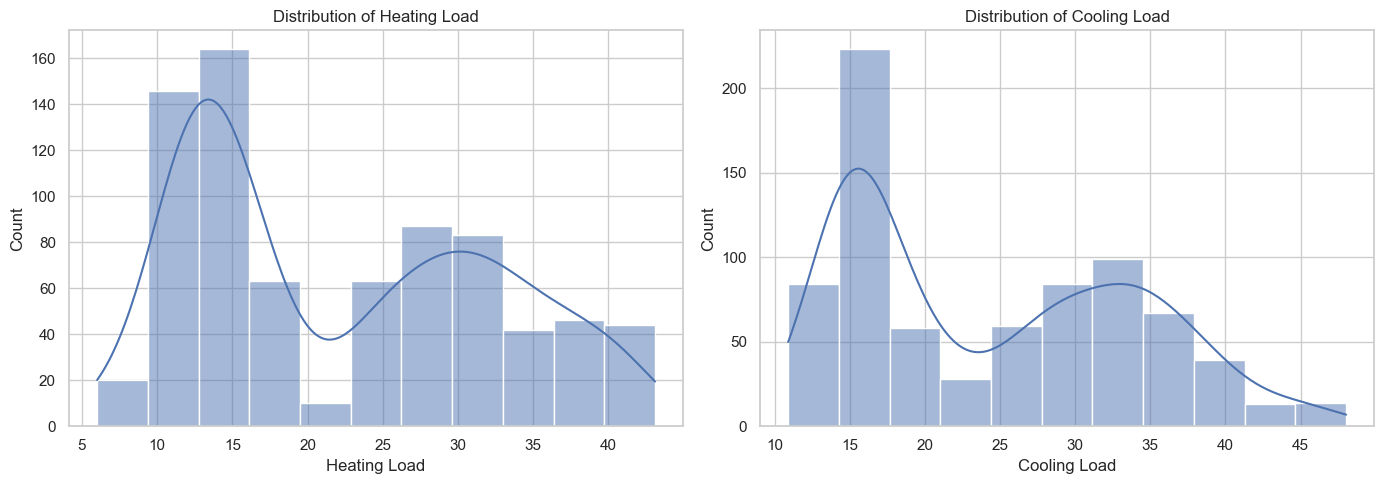

In [9]:
# Check the distributions of both target variables

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Heating_Load"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of Heating Load")
axes[0].set_xlabel("Heating Load")

sns.histplot(df["Cooling_Load"], kde=True, ax=axes[1])
axes[1].set_title("Distribution of Cooling Load")
axes[1].set_xlabel("Cooling Load")

plt.tight_layout()
plt.show()

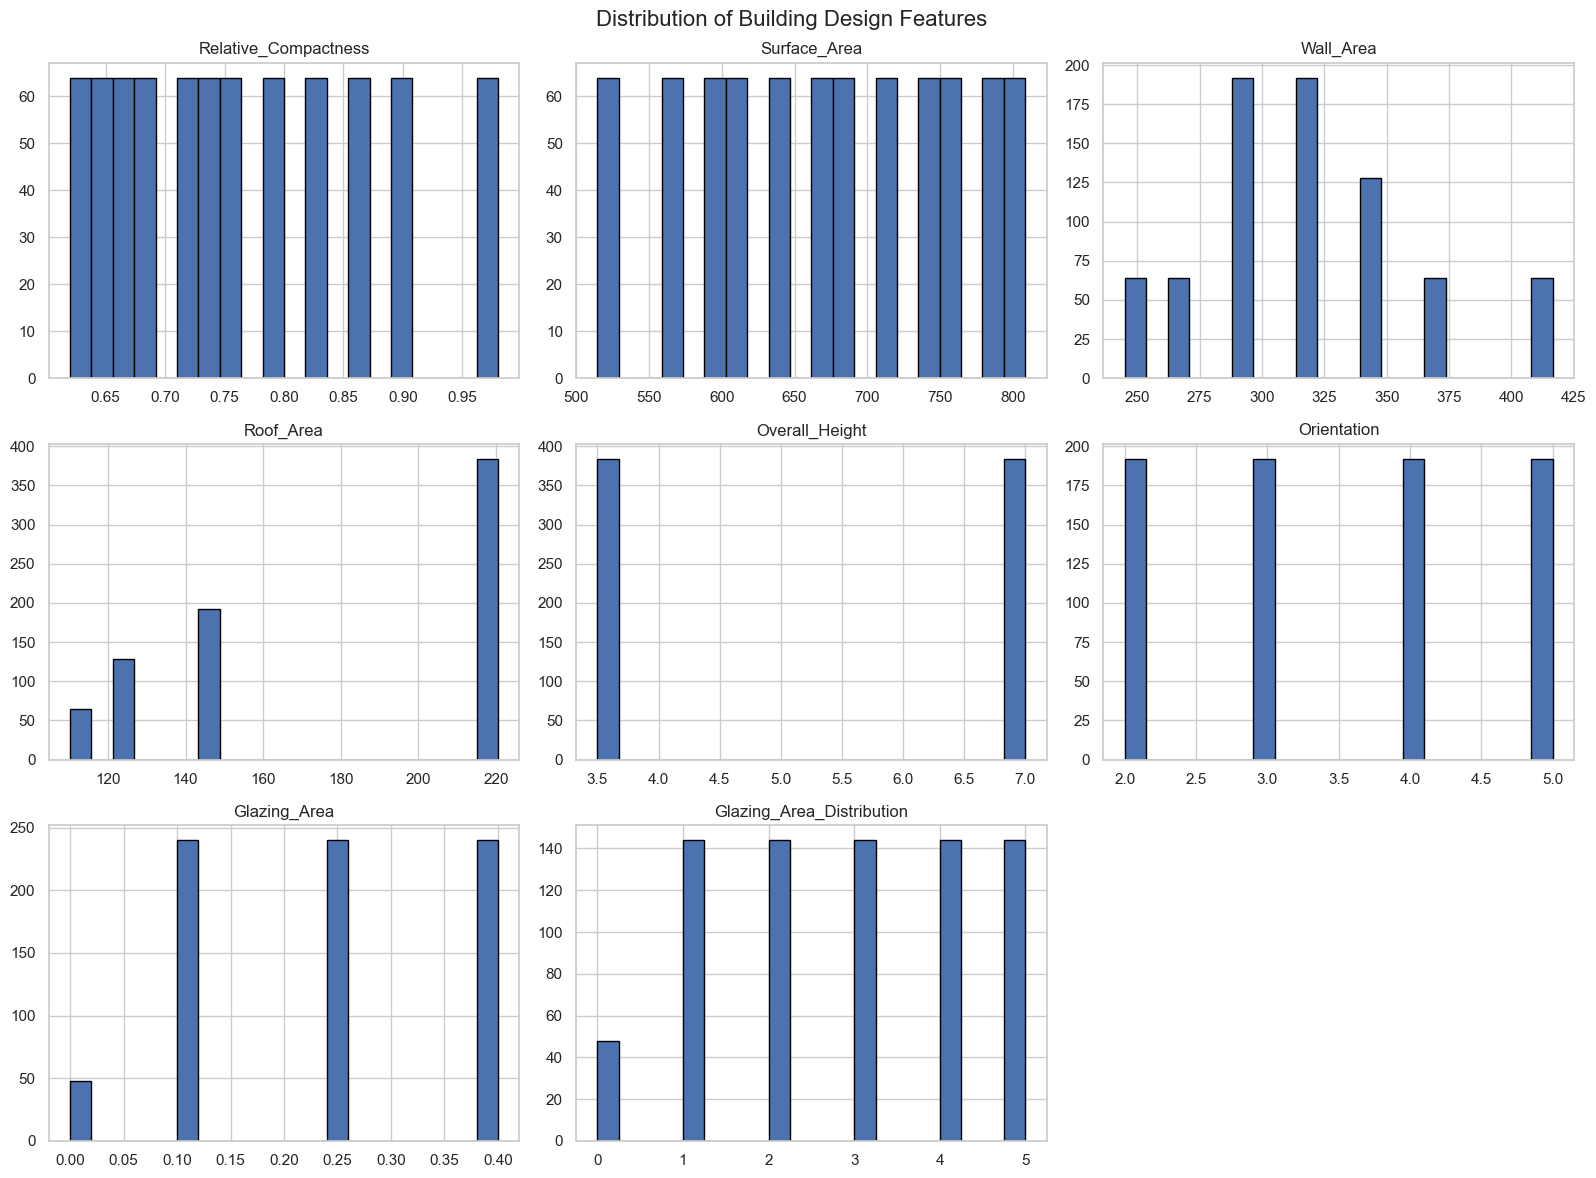

In [10]:
# Visualize distributions of all eight input features

features = df.columns[:8]

df[features].hist(figsize=(16, 12), bins=20, edgecolor="black")

plt.suptitle("Distribution of Building Design Features", fontsize=16)
plt.tight_layout()
plt.show()

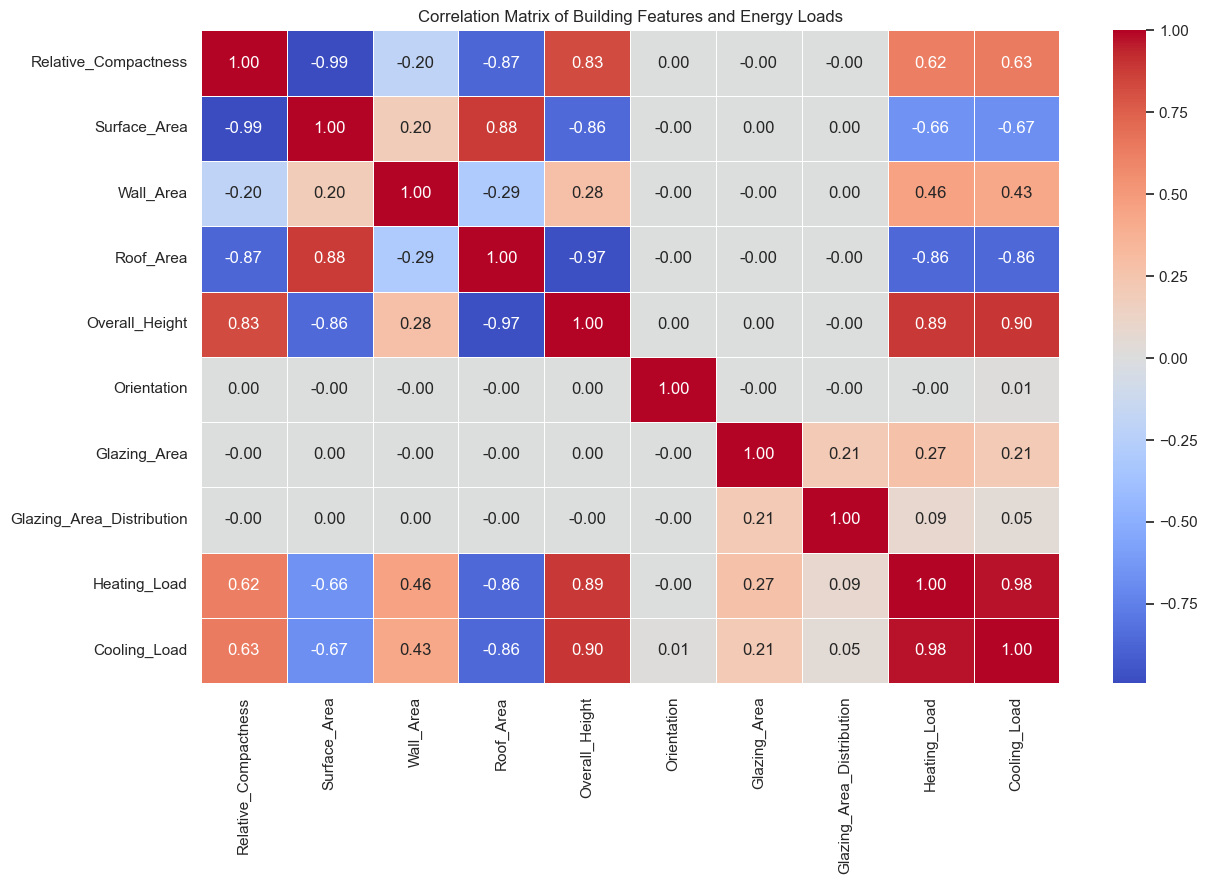

In [11]:
# Calculate Pearson correlation coefficients

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Building Features and Energy Loads")
plt.tight_layout()
plt.show()

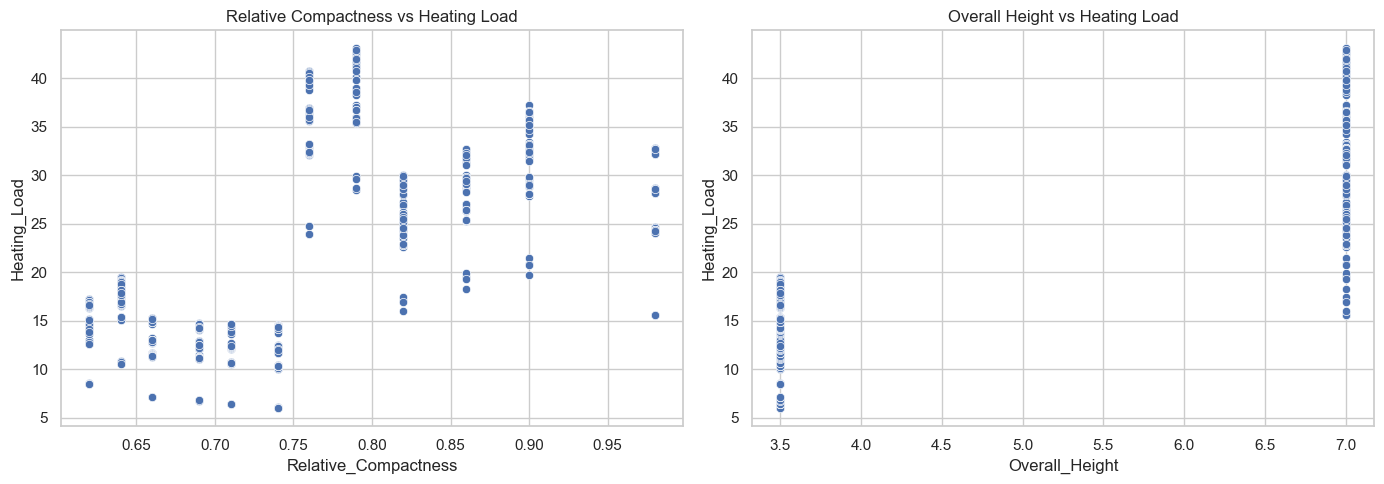

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df,
    x="Relative_Compactness",
    y="Heating_Load",
    ax=axes[0]
)
axes[0].set_title("Relative Compactness vs Heating Load")

sns.scatterplot(
    data=df,
    x="Overall_Height",
    y="Heating_Load",
    ax=axes[1]
)
axes[1].set_title("Overall Height vs Heating Load")

plt.tight_layout()
plt.show()

In [13]:
# Input features
X = df.iloc[:, :8].copy()

# Regression target
y = df["Heating_Load"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (768, 8)
Target shape: (768,)

Features:
['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Orientation', 'Glazing_Area', 'Glazing_Area_Distribution']


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (614, 8)
Testing features: (154, 8)
Training targets: (614,)
Testing targets: (154,)


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (614, 8)
Scaled testing shape: (154, 8)


In [16]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline MAE:", mean_absolute_error(y_test, baseline_predictions))
print("Baseline MSE:", mean_squared_error(y_test, baseline_predictions))
print("Baseline RMSE:", np.sqrt(mean_squared_error(y_test, baseline_predictions)))
print("Baseline R2:", r2_score(y_test, baseline_predictions))

Baseline MAE: 9.272077076018444
Baseline MSE: 104.8074236135235
Baseline RMSE: 10.237549687963595
Baseline R2: -0.005524947671173619


In [17]:
# Select one feature
X_train_simple = X_train[["Overall_Height"]]
X_test_simple = X_test[["Overall_Height"]]

# Create and train the model
simple_lr = LinearRegression()
simple_lr.fit(X_train_simple, y_train)

# Make predictions
y_pred_simple = simple_lr.predict(X_test_simple)

print("Intercept:", simple_lr.intercept_)
print("Coefficient:", simple_lr.coef_[0])

Intercept: -4.5005845644421605
Coefficient: 5.104974710719739


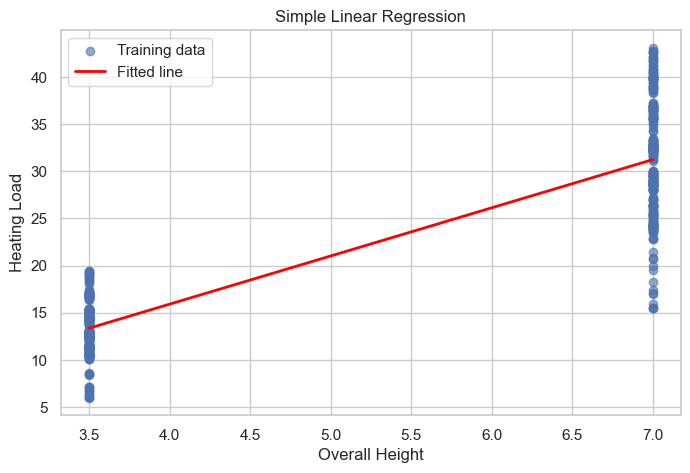

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_train["Overall_Height"],
    y_train,
    alpha=0.6,
    label="Training data"
)

# Sort x-values so the fitted line is plotted in order
x_line = np.linspace(
    X_train["Overall_Height"].min(),
    X_train["Overall_Height"].max(),
    100
)

y_line = simple_lr.predict(pd.DataFrame({
    "Overall_Height": x_line
}))

plt.plot(x_line, y_line, color="red", linewidth=2, label="Fitted line")

plt.xlabel("Overall Height")
plt.ylabel("Heating Load")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [19]:
multiple_lr = LinearRegression()

multiple_lr.fit(X_train, y_train)

y_pred_multiple = multiple_lr.predict(X_test)

print("Intercept:", multiple_lr.intercept_)

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": multiple_lr.coef_
})

coefficients

Intercept: 79.72697958259295


,Feature,Coefficient
0,Relative_Compactness,-61.873354
1,Surface_Area,-0.060105
2,Wall_Area,0.037553
3,Roof_Area,-0.048829
4,Overall_Height,4.123669
5,Orientation,-0.032439
6,Glazing_Area,20.143192
7,Glazing_Area_Distribution,0.211103


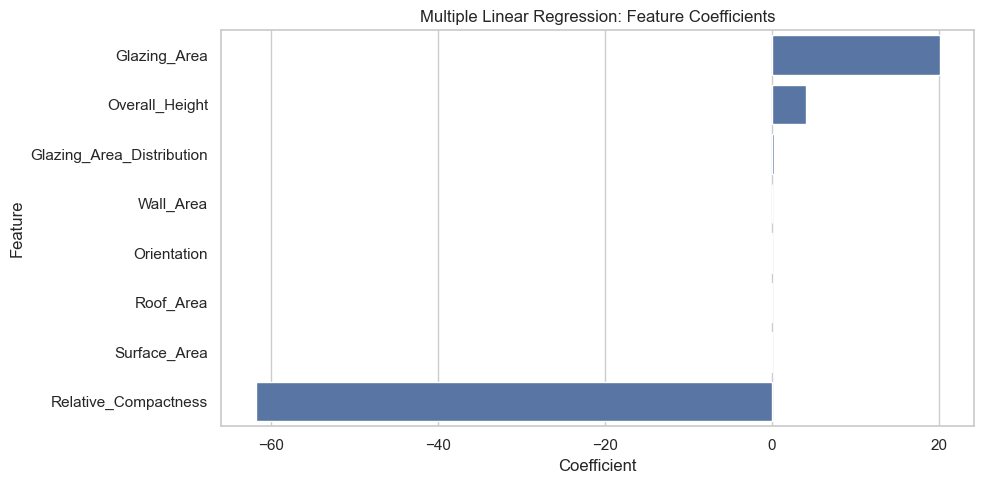

In [20]:
coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Multiple Linear Regression: Feature Coefficients")
plt.tight_layout()
plt.show()

In [21]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

polynomial_lr = LinearRegression()
polynomial_lr.fit(X_train_poly, y_train)

y_pred_polynomial = polynomial_lr.predict(X_test_poly)

print("Polynomial Regression trained successfully!")

Polynomial Regression trained successfully!


In [22]:
def evaluate_regression(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

In [23]:
regression_results = pd.DataFrame({
    "Simple Linear Regression": evaluate_regression(
        y_test, y_pred_simple
    ),
    "Multiple Linear Regression": evaluate_regression(
        y_test, y_pred_multiple
    ),
    "Polynomial Regression": evaluate_regression(
        y_test, y_pred_polynomial
    )
}).T

regression_results = regression_results.sort_values("RMSE")

regression_results.round(4)

,MAE,MSE,RMSE,R2
Polynomial Regression,0.6042,0.6447,0.8030,0.9938
Multiple Linear Regression,2.1820,9.1532,3.0254,0.9122
Simple Linear Regression,3.6441,21.6798,4.6562,0.7920


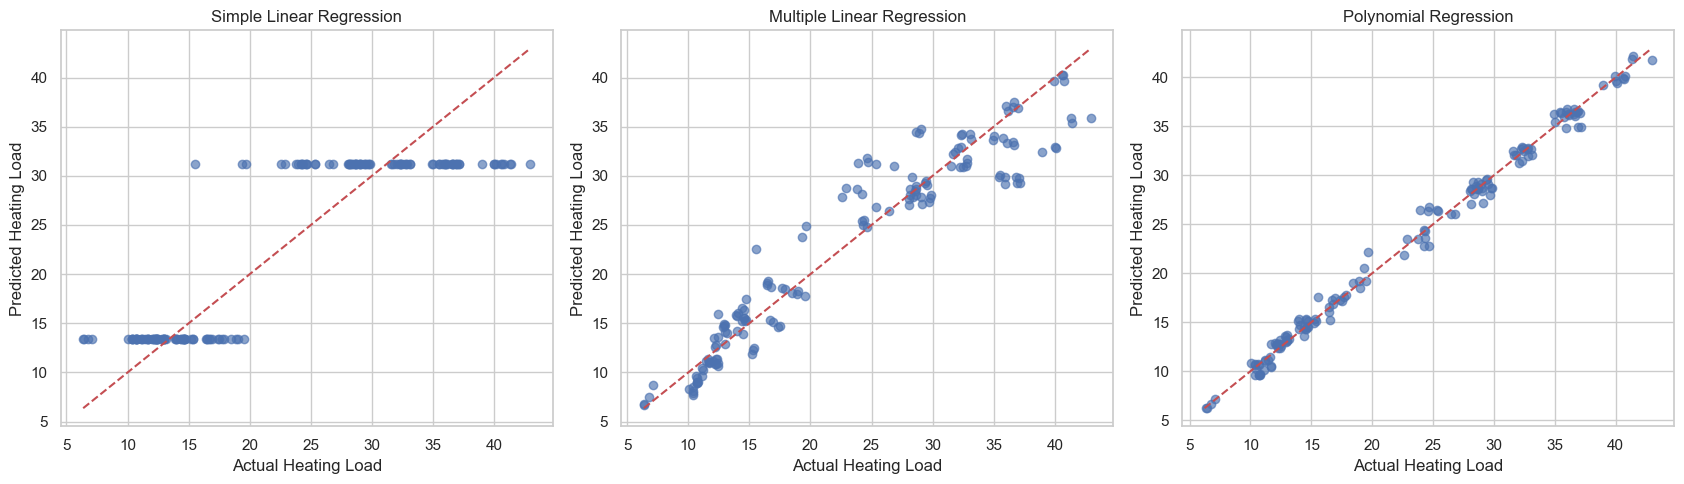

In [24]:
predictions = {
    "Simple Linear Regression": y_pred_simple,
    "Multiple Linear Regression": y_pred_multiple,
    "Polynomial Regression": y_pred_polynomial
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.65)

    lower = min(y_test.min(), pred.min())
    upper = max(y_test.max(), pred.max())

    ax.plot([lower, upper], [lower, upper], "r--")

    ax.set_title(name)
    ax.set_xlabel("Actual Heating Load")
    ax.set_ylabel("Predicted Heating Load")

plt.tight_layout()
plt.show()

In [25]:
regression_results.to_csv(
    "energywise_regression_results.csv",
    index=True
)

coefficients.to_csv(
    "energywise_regression_coefficients.csv",
    index=False
)

print("Regression results saved successfully.")

Regression results saved successfully.


In [26]:
# Define the threshold using training data only
heating_threshold = y_train.median()

# Encode low load as 0 and high load as 1
y_train_class = (y_train > heating_threshold).astype(int)
y_test_class = (y_test > heating_threshold).astype(int)

print("Heating-load threshold:", heating_threshold)

print("\nTraining class counts:")
print(y_train_class.value_counts().sort_index())

print("\nTesting class counts:")
print(y_test_class.value_counts().sort_index())

Heating-load threshold: 18.25

Training class counts:
Heating_Load
0    307
1    307
Name: count, dtype: int64

Testing class counts:
Heating_Load
0    69
1    85
Name: count, dtype: int64


In [27]:
class_distribution = pd.DataFrame({
    "Training": y_train_class.value_counts(normalize=True),
    "Testing": y_test_class.value_counts(normalize=True)
}).rename(index={0: "Low load", 1: "High load"})

class_distribution

,Training,Testing
Heating_Load,,
High load,0.5,0.551948
Low load,0.5,0.448052


In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic_model = LogisticRegression(max_iter=2000)
logistic_model.fit(X_train_scaled, y_train_class)

y_pred_logistic = logistic_model.predict(X_test_scaled)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

In [29]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree_model.fit(X_train, y_train_class)

y_pred_tree = decision_tree_model.predict(X_test)
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


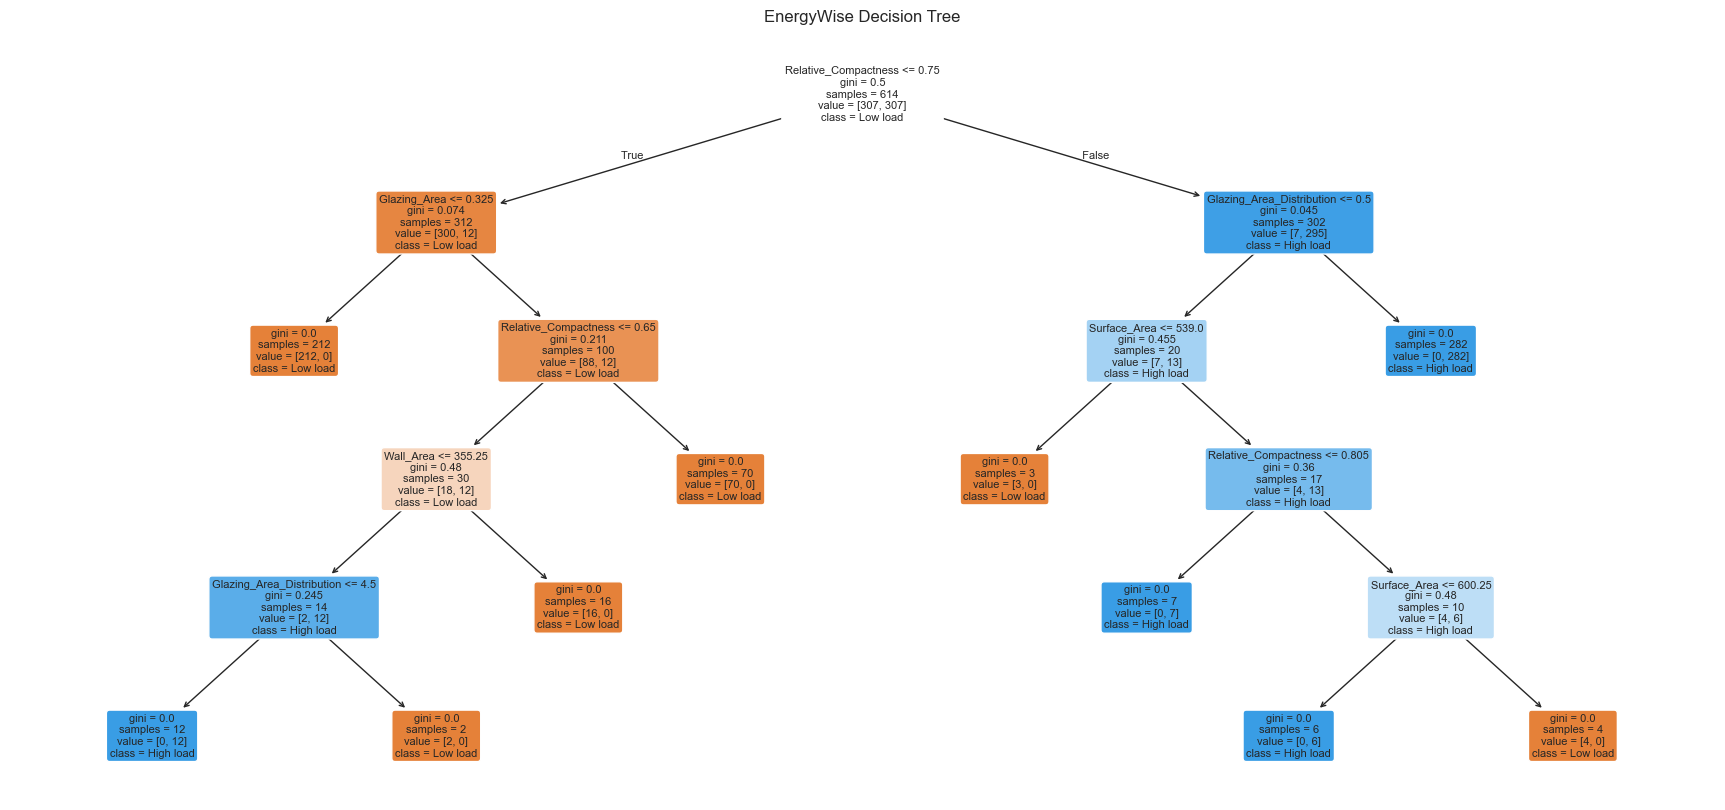

In [30]:
plt.figure(figsize=(22, 10))

plot_tree(
    decision_tree_model,
    feature_names=X_train.columns,
    class_names=["Low load", "High load"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("EnergyWise Decision Tree")
plt.show()

In [31]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train_class)

y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

In [32]:
def evaluate_classifier(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Log Loss": log_loss(
            y_true, y_prob, labels=[0, 1]
        )
    }

In [33]:
classification_results = pd.DataFrame({
    "Logistic Regression": evaluate_classifier(
        y_test_class,
        y_pred_logistic,
        y_prob_logistic
    ),
    "Decision Tree": evaluate_classifier(
        y_test_class,
        y_pred_tree,
        y_prob_tree
    ),
    "SVM": evaluate_classifier(
        y_test_class,
        y_pred_svm,
        y_prob_svm
    )
}).T

classification_results.round(4)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
Logistic Regression,0.9675,0.9878,0.9529,0.9701,0.9951,0.0900
Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
SVM,0.9675,0.9878,0.9529,0.9701,0.9957,0.1141


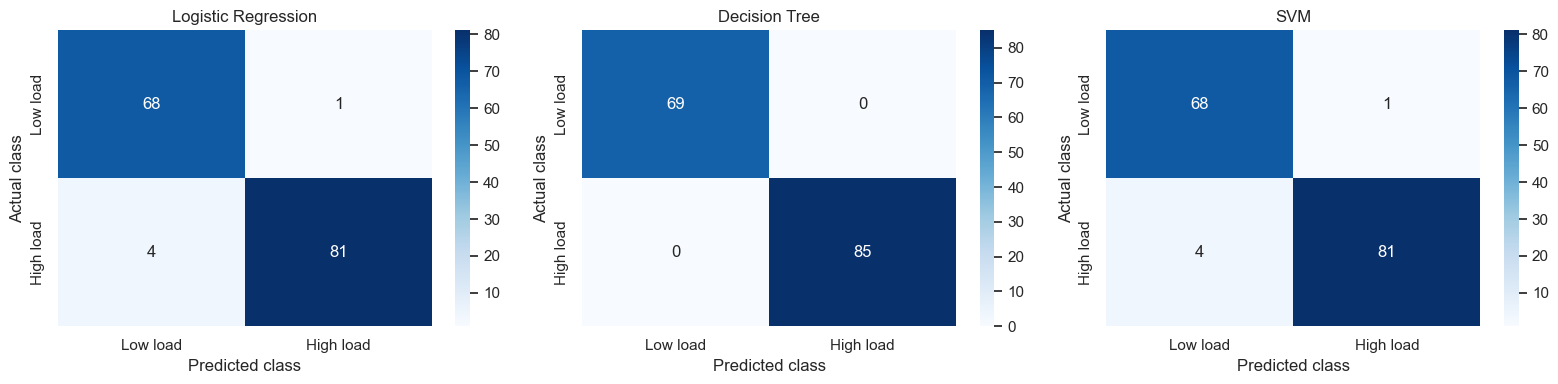

In [34]:
model_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "SVM": y_pred_svm
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, predictions) in zip(
    axes, model_predictions.items()
):
    cm = confusion_matrix(
        y_test_class,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low load", "High load"],
        yticklabels=["Low load", "High load"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

In [35]:
for name, predictions in model_predictions.items():
    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)

    print(
        classification_report(
            y_test_class,
            predictions,
            labels=[0, 1],
            target_names=["Low load", "High load"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

    Low load       0.94      0.99      0.96        69
   High load       0.99      0.95      0.97        85

    accuracy                           0.97       154
   macro avg       0.97      0.97      0.97       154
weighted avg       0.97      0.97      0.97       154


Decision Tree
              precision    recall  f1-score   support

    Low load       1.00      1.00      1.00        69
   High load       1.00      1.00      1.00        85

    accuracy                           1.00       154
   macro avg       1.00      1.00      1.00       154
weighted avg       1.00      1.00      1.00       154


SVM
              precision    recall  f1-score   support

    Low load       0.94      0.99      0.96        69
   High load       0.99      0.95      0.97        85

    accuracy                           0.97       154
   macro avg       0.97      0.97      0.97       154
weighted avg       0.97      0.97

In [36]:
classification_results.to_csv(
    "energywise_classification_results.csv"
)

print("Classification results saved successfully.")

Classification results saved successfully.


In [37]:
# Use building design features only
X_cluster = df.iloc[:, :8].copy()

# Standardize the features
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)

print("Original feature shape:", X_cluster.shape)
print("Scaled feature shape:", X_cluster_scaled.shape)
print("Feature means after scaling:")
print(np.round(X_cluster_scaled.mean(axis=0), 3))

Original feature shape: (768, 8)
Scaled feature shape: (768, 8)
Feature means after scaling:
[-0. -0.  0.  0.  0.  0.  0.  0.]


In [43]:
print("Regression results:")
display(regression_results.round(4))

print("\nClassification results:")
display(classification_results.round(4))


Regression results:


,MAE,MSE,RMSE,R2
Polynomial Regression,0.6042,0.6447,0.8030,0.9938
Multiple Linear Regression,2.1820,9.1532,3.0254,0.9122
Simple Linear Regression,3.6441,21.6798,4.6562,0.7920



Classification results:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
Logistic Regression,0.9675,0.9878,0.9529,0.9701,0.9951,0.0900
Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
SVM,0.9675,0.9878,0.9529,0.9701,0.9957,0.1141


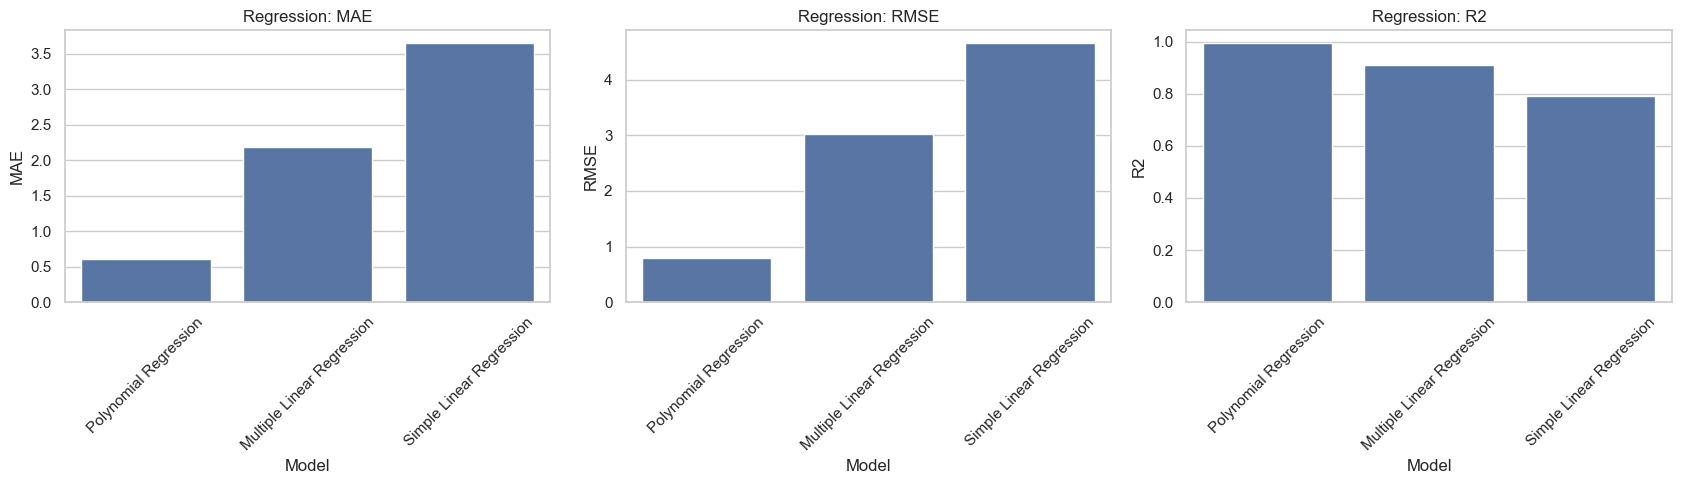

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["MAE", "RMSE", "R2"]

for ax, metric in zip(axes, metrics):
    sns.barplot(
        x=regression_results.index,
        y=regression_results[metric],
        ax=ax
    )

    ax.set_title(f"Regression: {metric}")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

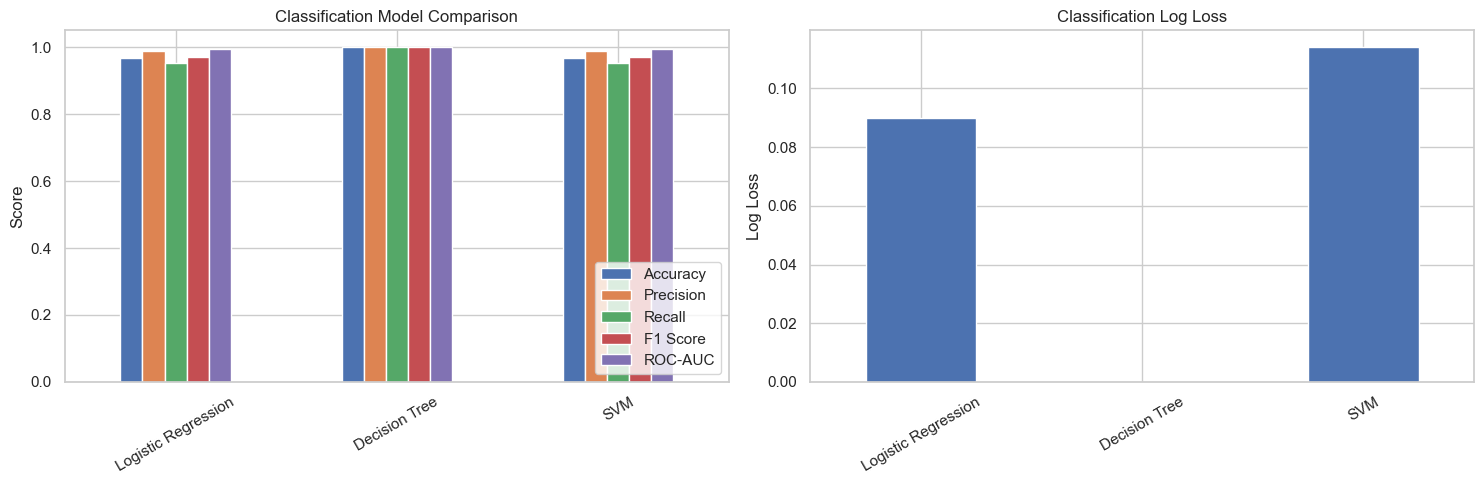

In [45]:
classification_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

classification_results[classification_metrics].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Classification Model Comparison")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(loc="lower right")

classification_results["Log Loss"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Classification Log Loss")
axes[1].set_ylabel("Log Loss")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [46]:
print(
    "Best regression model by RMSE:",
    regression_results["RMSE"].idxmin()
)

print(
    "Best regression model by R2:",
    regression_results["R2"].idxmax()
)

print(
    "Best classification model by F1:",
    classification_results["F1 Score"].idxmax()
)

print(
    "Best classification model by ROC-AUC:",
    classification_results["ROC-AUC"].idxmax()
)

print(
    "Best classification model by log loss:",
    classification_results["Log Loss"].idxmin()
)

Best regression model by RMSE: Polynomial Regression
Best regression model by R2: Polynomial Regression
Best classification model by F1: Decision Tree
Best classification model by ROC-AUC: Decision Tree
Best classification model by log loss: Decision Tree
